# Fractal Image Detector: quickstart

Point the notebook at a folder of images and it will measure fractal features, train a
detector, evaluate it, and explain individual predictions. Expected layout
(`validation` may also be `valid`/`val`; `synthetic` may also be `fake`/`ai`; splits are optional):

```
data/
├── train/       ├── real/       *.jpg  *.png ...
│                └── synthetic/
├── validation/  ├── real/ ...
└── test/        └── synthetic/ ...
```

## 1. Point to your data

In [1]:
import os
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from sklearn.metrics import roc_curve
from sklearn.model_selection import train_test_split

from fractal_detector import (
    DataSource,
    Detector,
    FeatureConfig,
    TrainingConfig,
    extract,
    iter_sources,
    native_available,
    train_splits,
)
from fractal_detector.features import noise_residual
from fractal_detector.io import load_image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/fractal_detector").is_dir())

# >>> Change this to your own dataset directory <<<
DATA_DIR = next(ROOT.glob("outputs/notebook-demo/sample-1337-*/images"))

MAX_PER_CLASS = None  # e.g. 50 caps every split/class for a quick trial run
WORKERS = min(8, os.cpu_count() or 1)
SEED = 1337
OUT = ROOT / "outputs" / "quickstart"
OUT.mkdir(parents=True, exist_ok=True)

COLORS = {"real": "#2a6fbb", "synthetic": "#d9662b"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
print(f"Data: {DATA_DIR}\nC kernels: {native_available()}, workers: {WORKERS}")

Data: D:\Pulpit\Fractal-Image-Detector\Fractal-synthetic-image-detector\outputs\notebook-demo\sample-1337-500-9be55ad838ce6753\images
C kernels: True, workers: 8


In [2]:
SPLIT_NAMES = {"train": ("train",), "validation": ("validation", "valid", "val"), "test": ("test",)}
CLASS_NAMES = {0: ("real", "authentic"), 1: ("synthetic", "fake", "ai", "generated")}


def find_dir(parent, names):
    return next((parent / n for n in names if (parent / n).is_dir()), None)


def load_split(folder):
    """Labeled samples from folder/<real|synthetic>/ (label 0 = real, 1 = synthetic)."""
    rng = np.random.default_rng(SEED)
    samples = []
    for label, names in CLASS_NAMES.items():
        if (class_dir := find_dir(folder, names)) is None:
            continue
        found = list(iter_sources([DataSource(paths=(str(class_dir),), label=label)]))
        if MAX_PER_CLASS and len(found) > MAX_PER_CLASS:
            found = [found[i] for i in sorted(rng.choice(len(found), MAX_PER_CLASS, replace=False))]
        samples += found
    return samples


splits = {k: load_split(d) for k, v in SPLIT_NAMES.items() if (d := find_dir(DATA_DIR, v))}
if not splits:  # no train/test folders: DATA_DIR/{real,synthetic} -> hold out 25% for testing
    everything = load_split(DATA_DIR)
    fit, held = train_test_split(
        everything, test_size=0.25, random_state=SEED, stratify=[s.label for s in everything]
    )
    splits = {"train": fit, "test": held}

counts = (
    pd.DataFrame(
        {
            k: pd.Series([s.label for s in v]).map({0: "real", 1: "synthetic"}).value_counts()
            for k, v in splits.items()
        }
    )
    .fillna(0)
    .astype(int)
)
counts

,train,validation,test
real,300,100,100
synthetic,300,100,100


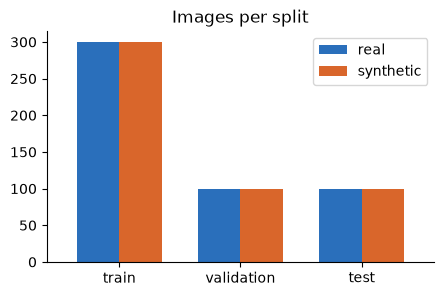

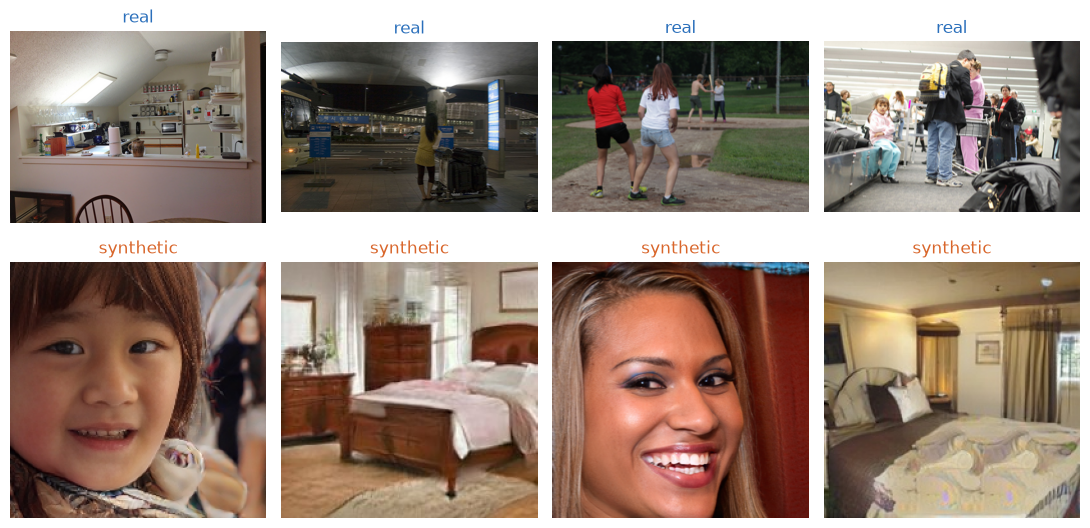

In [3]:
counts.T.plot.bar(color=COLORS, rot=0, figsize=(5, 3), width=0.7, title="Images per split")
plt.show()


def thumb(path, size=256):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
        im.thumbnail((size, size))
        return im.copy()


first = splits["train"]
picks = [s for s in first if s.label == 0][:4] + [s for s in first if s.label == 1][:4]
fig, axes = plt.subplots(2, 4, figsize=(11, 5.5))
for ax, s in zip(axes.ravel(), picks, strict=True):
    ax.imshow(thumb(s.path))
    name = "real" if s.label == 0 else "synthetic"
    ax.set_title(name, color=COLORS[name])
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Measure one image

`extract` returns 21 interpretable features: box-counting / differential **fractal dimensions**
(the slope of `log count` vs `log 1/scale`), lacunarity, residual entropy, spectral repetition
and fractal-compression self-similarity.

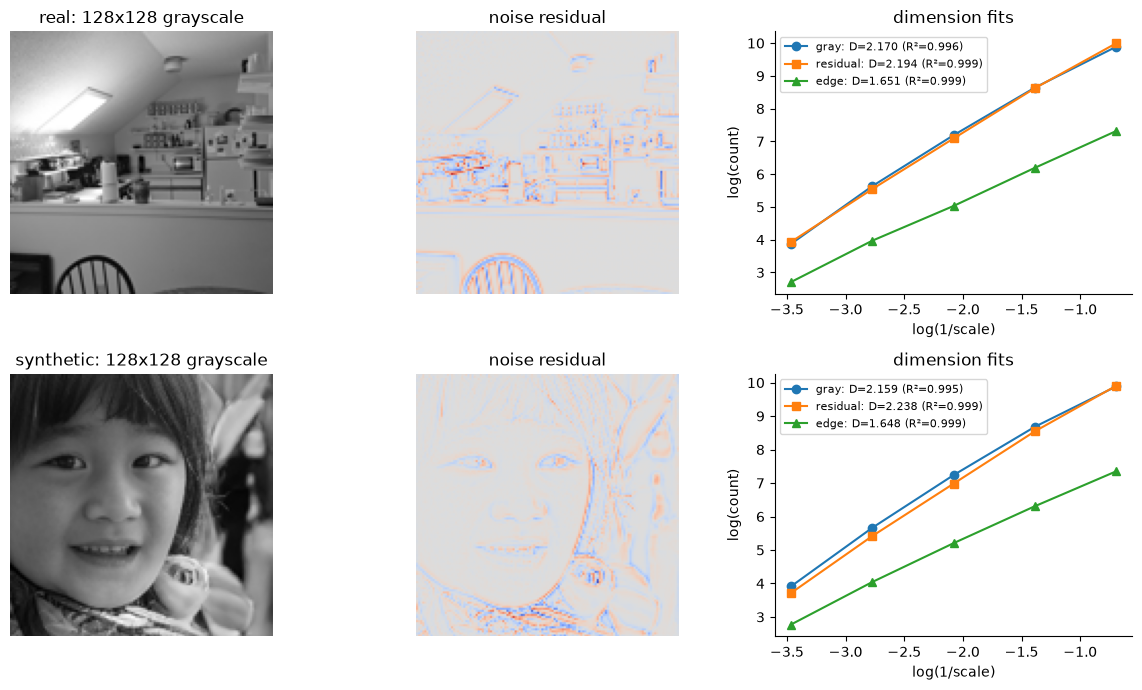

,real,synthetic
gray_dimension,2.1702,2.1591
gray_dimension_r2,0.9959,0.9952
residual_dimension,2.1936,2.2383
residual_dimension_r2,0.9992,0.9985
edge_dimension,1.6506,1.6477
edge_dimension_r2,0.9994,0.9985
edge_dimension_valid,1.0000,1.0000
residual_d0,2.0000,2.0000
residual_d1,1.8148,1.8702
residual_d2,1.7532,1.7939


In [4]:
cfg = FeatureConfig(image_size=128)  # Omit image_size to use the largest training image.
examples = {
    "real": next(s for s in splits["train"] if s.label == 0),
    "synthetic": next(s for s in splits["train"] if s.label == 1),
}
measured = {k: extract(s.path, cfg) for k, s in examples.items()}

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for row, (name, m) in zip(axes, measured.items(), strict=True):
    gray, *_ = load_image(examples[name].path, cfg)
    residual = noise_residual(gray, cfg)
    row[0].imshow(gray, cmap="gray")
    row[0].set_title(f"{name}: 128x128 grayscale")
    row[1].imshow(
        residual, cmap="coolwarm", vmin=-np.abs(residual).max(), vmax=np.abs(residual).max()
    )
    row[1].set_title("noise residual")
    for key, style in zip(("gray", "residual", "edge"), ("o-", "s-", "^-"), strict=True):
        d = m.dimensions[key]
        if d.value is None:
            continue
        x, y = np.log(1 / np.array(d.scales)), np.log(d.counts)
        row[2].plot(x, y, style, label=f"{key}: D={d.value:.3f} (R²={d.r_squared:.3f})")
    row[2].set(xlabel="log(1/scale)", ylabel="log(count)", title="dimension fits")
    row[2].legend(fontsize=8)
    for ax in row[:2]:
        ax.axis("off")
plt.tight_layout()
plt.show()

pd.DataFrame({k: m.features for k, m in measured.items()}).round(4)

## 3. Train

`train_splits` fits a standardized logistic regression on **train only**, then scores every
other split. It rejects duplicate images and shared groups across splits.

In [5]:
started = perf_counter()
result = train_splits(
    splits["train"],
    splits.get("validation"),
    splits.get("test"),
    feature_config=cfg,
    training_config=TrainingConfig(seed=SEED, class_weight="balanced"),
    workers=WORKERS,
)
detector = result.detector
detector.save(OUT / "model.json")
n = sum(len(v) for v in splits.values())
print(f"Measured {n} images and trained in {perf_counter() - started:.0f}s -> {OUT / 'model.json'}")

Measured 1000 images and trained in 24s -> D:\Pulpit\Fractal-Image-Detector\Fractal-synthetic-image-detector\outputs\quickstart\model.json


## 4. Evaluate

,validation,test
accuracy,0.720,0.760
balanced_accuracy,0.720,0.760
roc_auc,0.814,0.815
average_precision,0.794,0.803
log_loss,0.604,0.531
brier_score,0.177,0.177


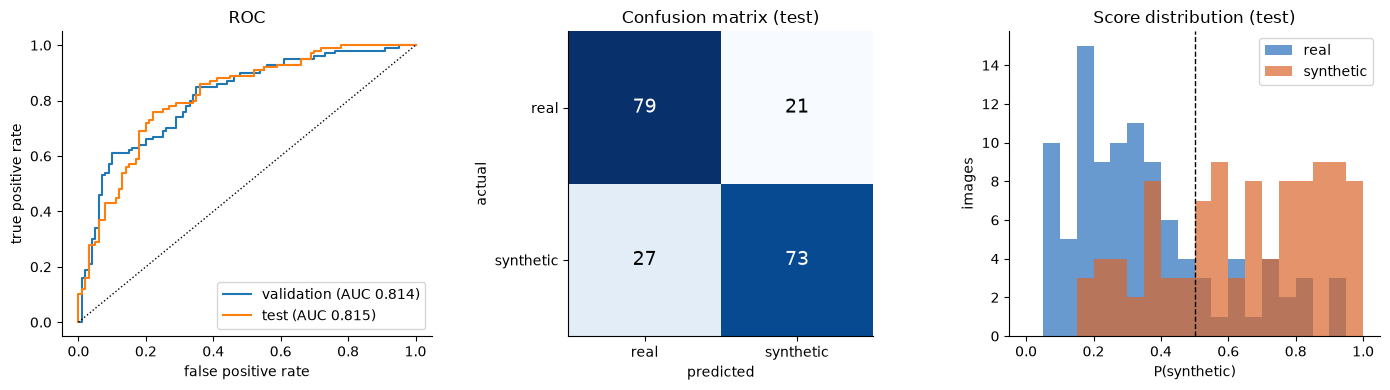

In [6]:
metrics = pd.DataFrame({k: e.metrics for k, e in result.evaluations.items()}).round(3)
display(metrics)

held = list(result.evaluations)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for name in held:
    e = result.evaluations[name]
    y = [s.label for s in splits[name]]
    p = [pr.synthetic_probability for pr in e.predictions]
    fpr, tpr, _ = roc_curve(y, p)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {e.metrics['roc_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], "k:", lw=1)
axes[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC")
axes[0].legend()

last = held[-1]
e = result.evaluations[last]
cm = np.array(e.confusion_matrix)
axes[1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    axes[1].text(
        j,
        i,
        v,
        ha="center",
        va="center",
        fontsize=14,
        color="white" if v > cm.max() / 2 else "black",
    )
axes[1].set(
    xticks=[0, 1],
    yticks=[0, 1],
    xticklabels=["real", "synthetic"],
    yticklabels=["real", "synthetic"],
    xlabel="predicted",
    ylabel="actual",
    title=f"Confusion matrix ({last})",
)

y = np.array([s.label for s in splits[last]])
p = np.array([pr.synthetic_probability for pr in e.predictions])
bins = np.linspace(0, 1, 21)
for label, name in ((0, "real"), (1, "synthetic")):
    axes[2].hist(p[y == label], bins=bins, alpha=0.7, color=COLORS[name], label=name)
axes[2].axvline(detector.artifact.threshold, color="k", ls="--", lw=1)
axes[2].set(xlabel="P(synthetic)", ylabel="images", title=f"Score distribution ({last})")
axes[2].legend()
plt.tight_layout()
plt.show()

## 5. What separates real from synthetic?

The model is linear over standardized features, so its weights are directly readable:
positive → pushes toward *synthetic*.

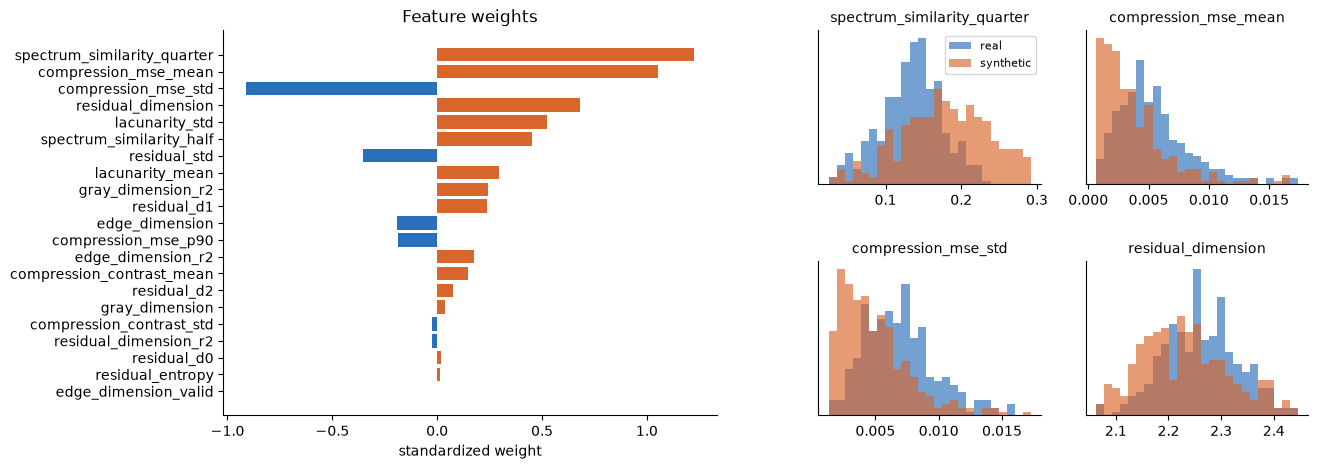

In [7]:
weights = pd.Series(detector.artifact.coefficients, index=detector.artifact.feature_names)
weights = weights.reindex(weights.abs().sort_values().index)

train_features = pd.DataFrame([m.features for m in result.measurements["train"]])
train_features["class"] = ["synthetic" if s.label else "real" for s in splits["train"]]
top = list(weights.abs().sort_values(ascending=False).index[:4])

fig = plt.figure(figsize=(14, 5))
ax = fig.add_subplot(1, 2, 1)
ax.barh(
    weights.index,
    weights.values,
    color=[COLORS["synthetic"] if w > 0 else COLORS["real"] for w in weights],
)
ax.set(xlabel="standardized weight", title="Feature weights")
grid = fig.add_gridspec(2, 4, left=0.55, wspace=0.5, hspace=0.5)
for k, feat in enumerate(top):
    ax = fig.add_subplot(grid[k // 2, 2 * (k % 2) : 2 * (k % 2) + 2])
    lo, hi = train_features[feat].quantile([0.01, 0.99])  # ignore extreme outliers
    for name in ("real", "synthetic"):
        ax.hist(
            train_features.loc[train_features["class"] == name, feat],
            bins=25,
            range=(lo, hi),
            alpha=0.65,
            color=COLORS[name],
            label=name,
        )
    ax.set_title(feat, fontsize=10)
    ax.set_yticks([])
axes_all = fig.axes
axes_all[1].legend(fontsize=8)
plt.show()

## 6. Explain a single prediction

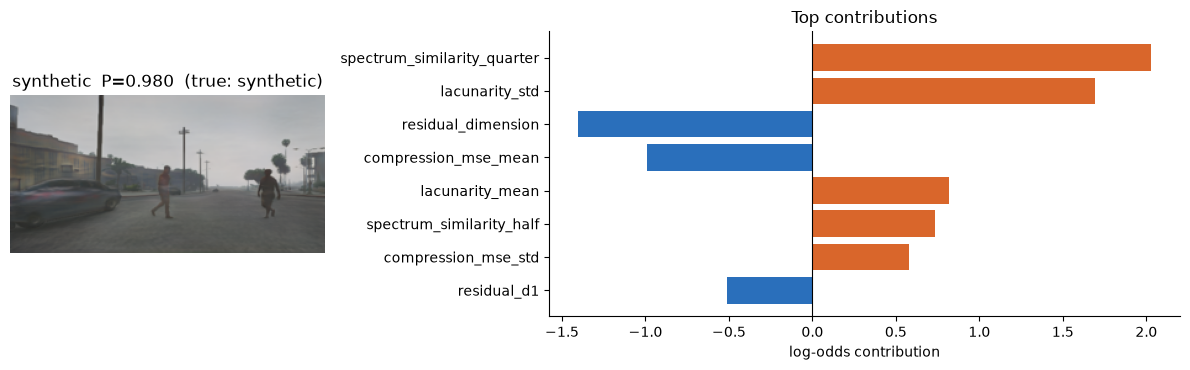

Classified as synthetic at threshold 0.500. Grayscale surface fractal dimension: 1.9826. Largest log-odds contributions: spectrum_similarity_quarter +2.030; lacunarity_std +1.692; residual_dimension -1.405. Positive terms favor synthetic. This is a learned statistical estimate, not proof of image provenance; probabilities are not independently calibrated.


In [8]:
e = result.evaluations[held[-1]]
i = int(np.argmax([pr.synthetic_probability for pr in e.predictions]))  # most 'synthetic' image
pr, sample = e.predictions[i], splits[held[-1]][i]
top8 = pr.contributions[:8]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 2]})
axes[0].imshow(thumb(sample.path))
axes[0].axis("off")
axes[0].set_title(
    f"{pr.label}  P={pr.synthetic_probability:.3f}  (true: {'synthetic' if sample.label else 'real'})"
)
axes[1].barh(
    [c.feature for c in top8][::-1],
    [c.log_odds for c in top8][::-1],
    color=[COLORS["synthetic"] if c.log_odds > 0 else COLORS["real"] for c in top8][::-1],
)
axes[1].axvline(0, color="k", lw=0.8)
axes[1].set(xlabel="log-odds contribution", title="Top contributions")
plt.tight_layout()
plt.show()
print(pr.explanation)

## 7. Use the trained model on new images

Load the saved model and score a single file or a whole (unlabeled) directory.
`on_error="skip"` reports unreadable files instead of stopping.

In [9]:
detector = Detector.load(OUT / "model.json")

NEW_IMAGES = (
    find_dir(DATA_DIR, SPLIT_NAMES["test"]) or DATA_DIR
)  # <- any folder of unlabeled images

single = detector.predict(splits["test"][0].path if "test" in splits else picks[0].path)
print(f"single image: {single.label} (P={single.synthetic_probability:.3f})")

outputs = list(detector.predict_directory(NEW_IMAGES, workers=WORKERS, on_error="skip"))
preds = [o for o in outputs if not hasattr(o, "error_type")]
failures = [o for o in outputs if hasattr(o, "error_type")]
table = pd.DataFrame(
    {
        "image": [p.measurement.source for p in preds],
        "label": [p.label for p in preds],
        "P(synthetic)": [round(p.synthetic_probability, 3) for p in preds],
    }
).sort_values("P(synthetic)", ascending=False, ignore_index=True)
print(
    f"{len(preds)} scored, {len(failures)} failed; {(table.label == 'synthetic').mean():.0%} flagged synthetic"
)
table.assign(image=table.image.map(lambda p: Path(p).name)).head(8)

single image: synthetic (P=0.937)


200 scored, 0 failed; 47% flagged synthetic


,image,label,P(synthetic)
0,train-00046-of-00057-row-2480.png,synthetic,0.980
1,train-00044-of-00057-row-2457.jpg,synthetic,0.974
2,train-00004-of-00057-row-927.jpg,synthetic,0.973
3,train-00010-of-00057-row-476.png,synthetic,0.972
4,train-00055-of-00057-row-465.png,synthetic,0.966
5,train-00033-of-00057-row-124.jpg,synthetic,0.965
6,validation-00000-of-00015-row-1333.jpg,synthetic,0.957
7,train-00008-of-00057-row-2327.jpg,synthetic,0.953


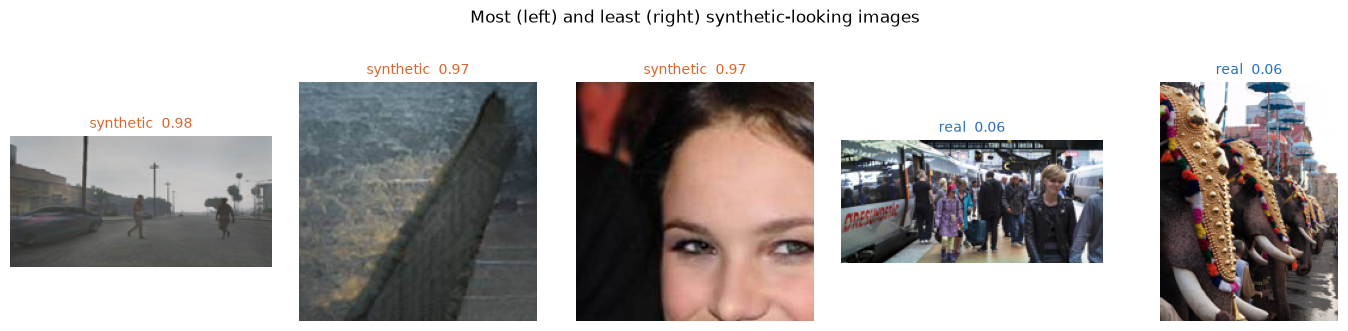

In [10]:
show = pd.concat([table.head(3), table.tail(2)])
fig, axes = plt.subplots(1, 5, figsize=(14, 3.2))
for ax, (_, r) in zip(axes, show.iterrows(), strict=True):
    ax.imshow(thumb(r["image"], 200))
    ax.axis("off")
    ax.set_title(f"{r['label']}  {r['P(synthetic)']:.2f}", fontsize=10, color=COLORS[r["label"]])
plt.suptitle("Most (left) and least (right) synthetic-looking images", y=1.02)
plt.tight_layout()
plt.show()

## Next steps

- Same workflow from the shell: `fractal-detector run configs/train-splits.toml`
  (also `predict`, `evaluate`, `extract`; optional MLflow tracking).
- Tune `FeatureConfig` (`image_size`, `scales`, `residual="svd"`, `compression=False`) and
  `TrainingConfig` (`regularization_c`, `threshold`).
- Keep related images in one `group` (CSV/Parquet manifests) to avoid leakage across splits;
  see `docs/data.md`. The model is a learned statistical estimate, not proof of provenance.